In [1]:
from microsim import schema as ms
from microsim.schema.detectors.lib import HYD_SP8
from microsim.schema.optical_config.lib import LASER_488
from microsim.util import ortho_plot

sim = ms.Simulation(
    truth_space=ms.ShapeScaleSpace(shape=(256, 512, 512), scale=(0.02, 0.01, 0.01)),
    output_space={"downscale": 8},
    sample=ms.Sample(
        labels=[
            ms.FluorophoreDistribution(
                distribution=ms.MatsLines(density=1, length=8, azimuth=10, max_r=0.9),
                fluorophore="EGFP",
            )
        ]
    ),
    # 488 nm laser; power is the peak irradiance at the focus (W/cm^2)
    channels=[LASER_488.model_copy(update={"power": 1e4})],
    modality=ms.Confocal(pinhole_au=0.4),
    detector=HYD_SP8,
    exposure_ms=0.001,  # 1 µs pixel dwell time
    settings=ms.Settings(random_seed=100),
    output_path="au1.tif",
)

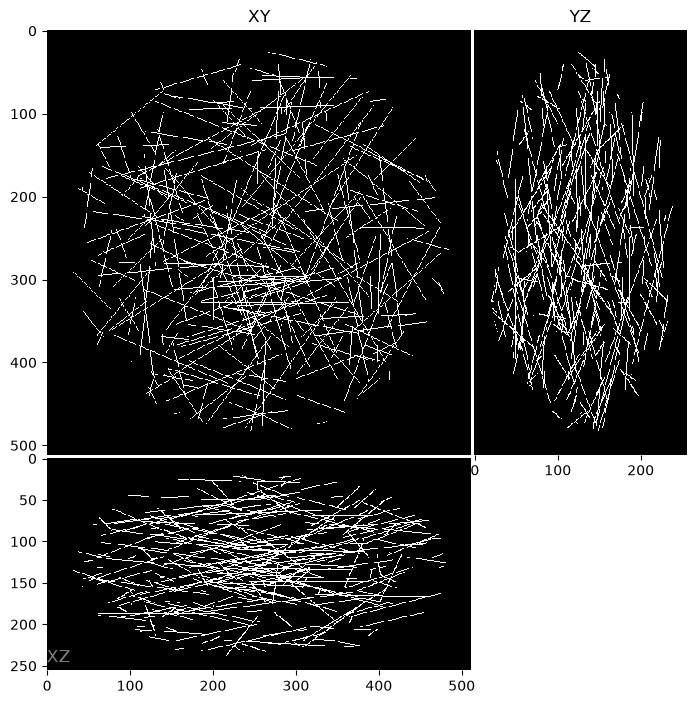

In [2]:
ground_truth = sim.ground_truth()
ortho_plot(ground_truth, mip=True)

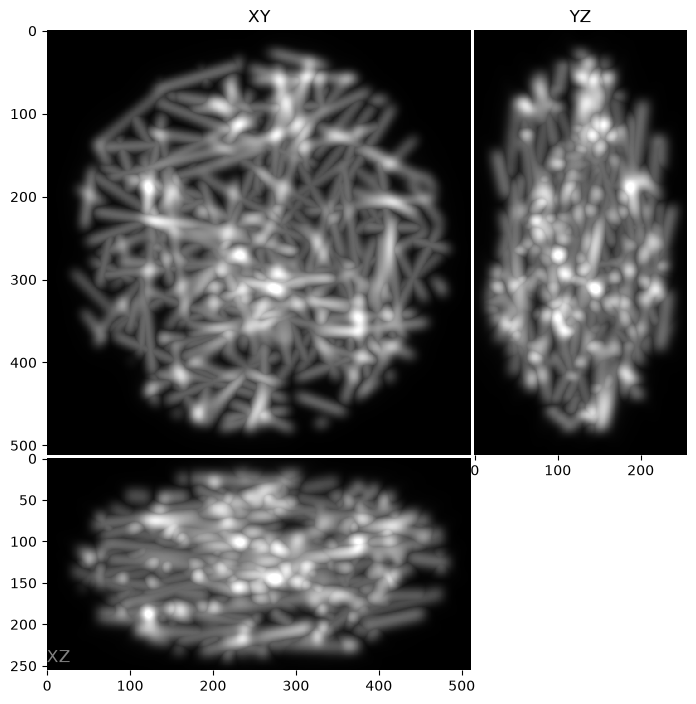

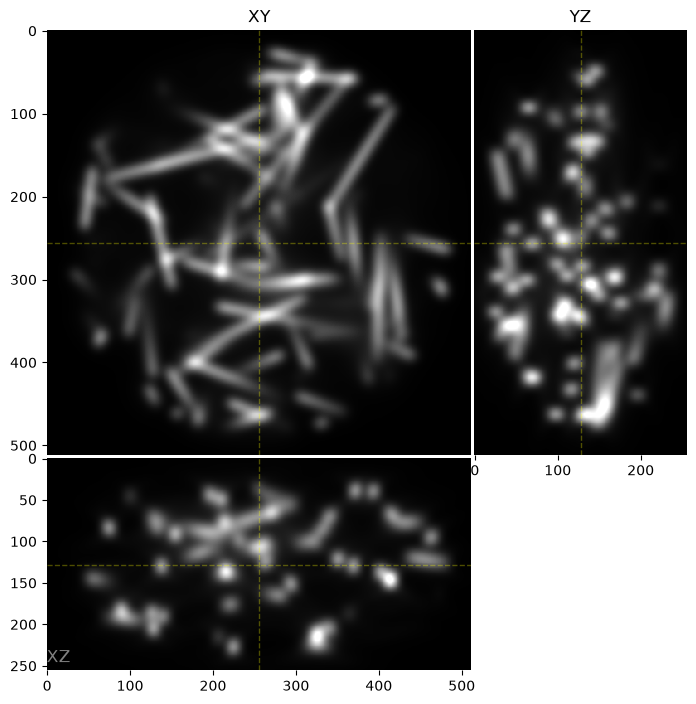

In [3]:
optical_img = sim.optical_image()
ortho_plot(optical_img, mip=True)
ortho_plot(optical_img, mip=False)

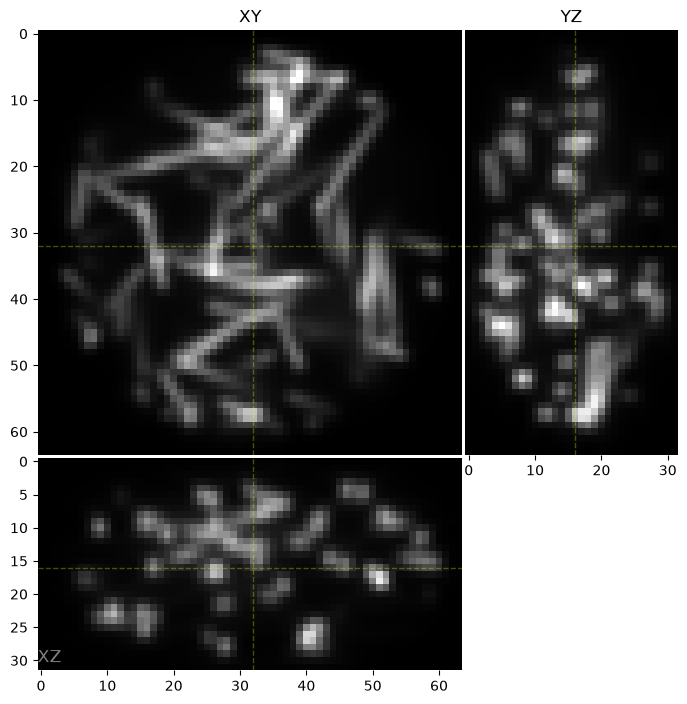

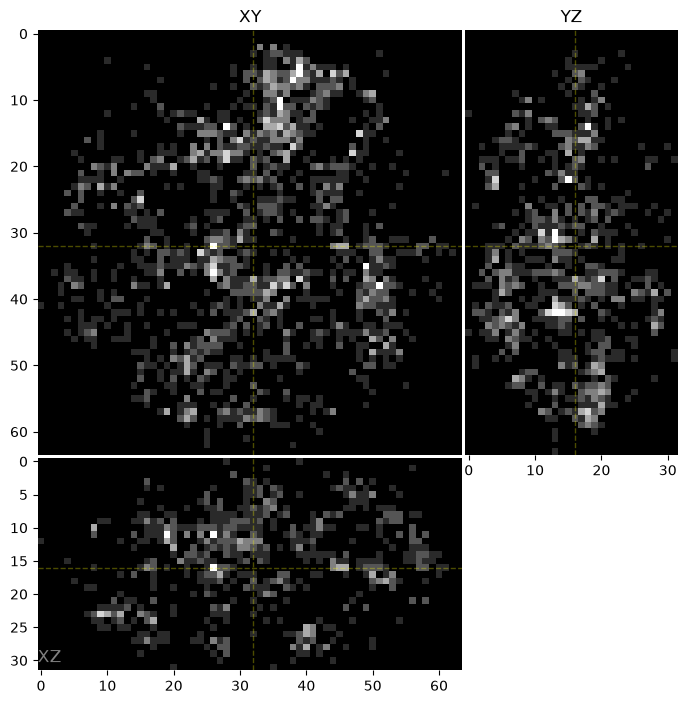

In [4]:
noise_free_digital_image = sim.digital_image(optical_img, with_detector_noise=False)
ortho_plot(noise_free_digital_image, mip=False)

realistic_digital_image = sim.digital_image(optical_img, with_detector_noise=True)
ortho_plot(realistic_digital_image, mip=False)

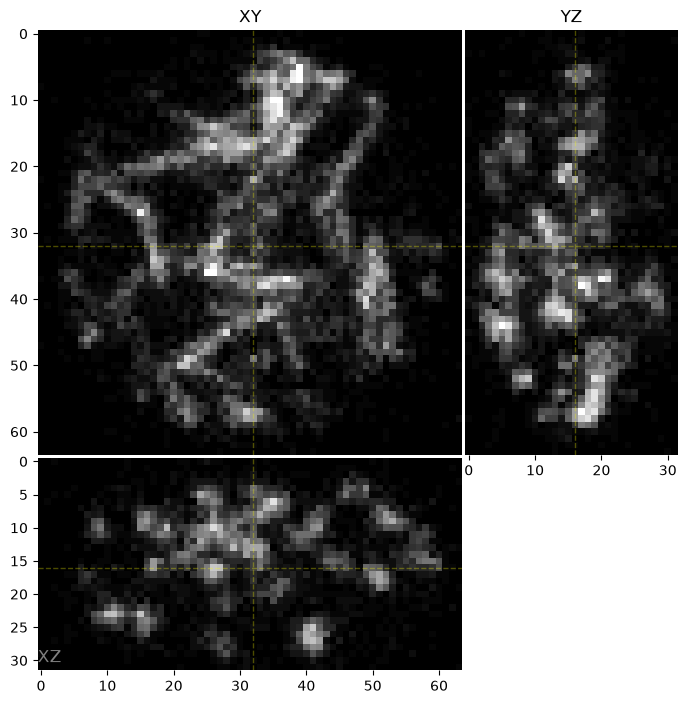

In [5]:
# longer pixel dwell time (more photons)
realistic_digital_image2 = sim.digital_image(optical_img, exposure_ms=0.01)
ortho_plot(realistic_digital_image2, mip=False)